# Egypt House Prices – Price Prediction (Regression)

**Problem statement:** buyers and sellers in Egypt need a fair estimate of a property's price before they negotiate.
The goal is to build a model that predicts the **price in EGP** of a property from its description
(type, size, rooms, city, compound, finishing, payment and delivery).

**Task type:** supervised **regression** – the target `Price` is a continuous number.

**Dataset:** 27,361 property listings, 12 columns (11 features + the target).

| Column | Meaning |
|---|---|
| Type | Apartment, Chalet, Villa, Town House, ... |
| **Price** | **Target** – price in EGP |
| Bedrooms / Bathrooms | number of rooms (`10+` means 10 or more) |
| Area | size in m² |
| Furnished | Yes / No / Unknown |
| Level | floor number, Ground, Highest or Unknown |
| Compound | compound name (or Unknown / Not in Compound) |
| Payment_Option | Cash / Installment / Cash or Installment |
| Delivery_Date | Ready to move, soon, a year, ... |
| Delivery_Term | Finished / Semi Finished / Not Finished / Core & Shell |
| City | city or area |

**Metrics:** R² (main), MAE, MSE, RMSE. All models are compared with **5-fold cross-validation on the training data**;
the test set is used only once, at the end.

# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_theme(style='whitegrid')

# Read data

In [2]:
df = pd.read_csv('../dataset/egypt_house_prices.csv', encoding='utf-8-sig')
df.head()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3,3,400,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3,3,160,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3,2,165,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3,2,230,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2,3,160,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


In [3]:
df.shape

(27361, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27361 entries, 0 to 27360
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Type            27179 non-null  object
 1   Price           27302 non-null  object
 2   Bedrooms        26938 non-null  object
 3   Bathrooms       26988 non-null  object
 4   Area            26824 non-null  object
 5   Furnished       27267 non-null  object
 6   Level           27284 non-null  object
 7   Compound        27219 non-null  object
 8   Payment_Option  27115 non-null  object
 9   Delivery_Date   27258 non-null  object
 10  Delivery_Term   27286 non-null  object
 11  City            27334 non-null  object
dtypes: object(12)
memory usage: 2.5+ MB


In [5]:
df.describe()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
count,27179,27302,26938,26988,26824,27267,27284,27219,27115,27258,27286,27334
unique,11,4180,12,12,785,3,14,559,4,10,5,183
top,Apartment,3000000,3,2,120,No,Unknown,Unknown,Cash or Installment,Ready to move,Finished,New Cairo - El Tagamoa
freq,8341,311,11677,9098,661,16447,10387,11013,10752,12094,14352,6771


# Data Understanding
- Every column is stored as **text**, even `Price`, `Area`, `Bedrooms` and `Bathrooms`, because the word `Unknown` is used instead of empty values.
- The target is `Price` → this is a **regression** problem.
- Let's look at the values of each column.

In [6]:
for col in df.columns:
    print(col, '->', df[col].nunique(), 'unique values, e.g.', df[col].unique()[:8])

Type -> 11 unique values, e.g. ['Duplex' 'Apartment' 'Penthouse' 'Studio' 'Unknown' nan 'Chalet'
 'Standalone Villa']
Price -> 4180 unique values, e.g. ['4000000' '2250000' '1900000' '5800000' '1844900' '3900000' '1650000'
 '1560000']
Bedrooms -> 12 unique values, e.g. ['3' '2' '4' '5' '1' 'Unknown' nan '7']
Bathrooms -> 12 unique values, e.g. ['3' '2' '5' '1' '4' 'Unknown' nan '7']
Area -> 785 unique values, e.g. ['400' '160' '165' '230' '222' '290' '144' '200']
Furnished -> 3 unique values, e.g. ['No' 'Unknown' 'Yes' nan]
Level -> 14 unique values, e.g. ['7' '10+' '1' '10' 'Ground' 'Highest' '3' '2']
Compound -> 559 unique values, e.g. ['Unknown' 'Eastown' 'Beit Al Watan' 'Jayd' 'Zayed 2000' '90 Avenue'
 'Armonia' 'Palm Hills New Cairo']
Payment_Option -> 4 unique values, e.g. ['Cash' 'Cash or Installment' 'Unknown Payment' 'Installment' nan]
Delivery_Date -> 10 unique values, e.g. ['Ready to move' '2024' 'Unknown' '2023' 'soon' '2025' 'within 6 months'
 '2022']
Delivery_Term -> 5 un

In [7]:
df['Type'].value_counts()

Type
Apartment            8341
Chalet               6593
Stand Alone Villa    4626
Town House           3074
Twin House           1793
Duplex                852
Standalone Villa      608
Penthouse             523
Twin house            483
Studio                250
Unknown                36
Name: count, dtype: int64

`Standalone Villa` / `Stand Alone Villa` and `Twin house` / `Twin House` are the same category written in two ways.

In [8]:
df[df['Price'] == 'Unknown'].head()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
216,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
1186,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
2793,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
3655,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
3830,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale


These rows are empty (every column is `Unknown`), so they have no value for training.

# Data Cleaning

## 1. Fix text values

In [9]:
# remove extra spaces (e.g. 'Unknown ' in Delivery_Term)
for col in df.columns:
    df[col] = df[col].str.strip()

# the same category written in two ways
df['Type'] = df['Type'].replace({'Standalone Villa': 'Stand Alone Villa', 'Twin house': 'Twin House'})
df['Type'].value_counts()

Type
Apartment            8341
Chalet               6593
Stand Alone Villa    5234
Town House           3074
Twin House           2276
Duplex                852
Penthouse             523
Studio                250
Unknown                36
Name: count, dtype: int64

## 2. Convert numeric columns from text to numbers

In [10]:
for col in ['Price', 'Bedrooms', 'Bathrooms', 'Area']:
    df[col] = df[col].replace('10+', '10')            # '10+' rooms -> 10
    df[col] = pd.to_numeric(df[col], errors='coerce')  # 'Unknown' -> NaN

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27361 entries, 0 to 27360
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Type            27179 non-null  object 
 1   Price           27265 non-null  float64
 2   Bedrooms        26902 non-null  float64
 3   Bathrooms       26952 non-null  float64
 4   Area            26788 non-null  float64
 5   Furnished       27267 non-null  object 
 6   Level           27284 non-null  object 
 7   Compound        27219 non-null  object 
 8   Payment_Option  27115 non-null  object 
 9   Delivery_Date   27258 non-null  object 
 10  Delivery_Term   27286 non-null  object 
 11  City            27334 non-null  object 
dtypes: float64(4), object(8)
memory usage: 2.5+ MB


## 3. Missing values

In [11]:
df.isnull().sum()

Type              182
Price              96
Bedrooms          459
Bathrooms         409
Area              573
Furnished          94
Level              77
Compound          142
Payment_Option    246
Delivery_Date     103
Delivery_Term      75
City               27
dtype: int64

- `Price` is the **target**: a row without a price can't be used for training or testing → **drop it**.
- Missing values in the **features** are filled later **inside the Pipeline** (median for numbers, `Unknown` for categories),
  so the fill values are learned from the **training data only** (no data leakage).
- `Unknown` inside a category (e.g. `Level = Unknown` for villas) is kept as its own category because it carries information.

In [12]:
df.dropna(subset=['Price'], inplace=True)
df.shape

(27265, 12)

## 4. Duplicates

In [13]:
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

Number of duplicate rows :  1862


(25403, 12)

Duplicates are removed **before** the train/test split, otherwise the same listing could be in both train and test (data leakage).

# EDA & Statistical Analysis

In [14]:
df[['Price', 'Area', 'Bedrooms', 'Bathrooms']].describe().round(1)

,Price,Area,Bedrooms,Bathrooms
count,25403.0,24908.0,25018.0,25068.0
mean,4835398.2,231.1,3.3,2.8
std,6909062.0,162.1,1.2,1.4
min,30000.0,10.0,1.0,1.0
25%,1139715.5,125.0,3.0,2.0
50%,2791000.0,177.0,3.0,3.0
75%,6000000.0,276.0,4.0,4.0
max,240000000.0,998.0,10.0,10.0


In [15]:
print('Price skewness     :', round(df['Price'].skew(), 2))
print('Price kurtosis     :', round(df['Price'].kurt(), 2))
print('log(Price) skewness:', round(np.log1p(df['Price']).skew(), 2))

Price skewness     : 6.79
Price kurtosis     : 116.24
log(Price) skewness: -0.26


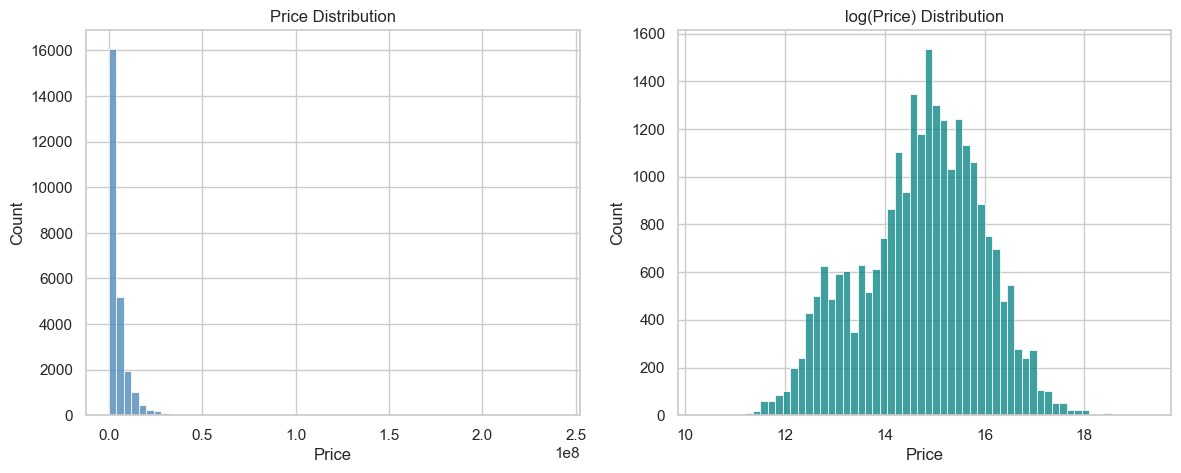

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Price'], bins=60, color='steelblue', ax=ax[0])
ax[0].set_title('Price Distribution')
sns.histplot(np.log1p(df['Price']), bins=60, color='teal', ax=ax[1])
ax[1].set_title('log(Price) Distribution')
plt.show()

The price is **very right-skewed** (few very expensive villas). After taking the log it becomes close to normal,
so the models will predict **log(Price)** and the prediction is converted back to EGP with `np.expm1`.

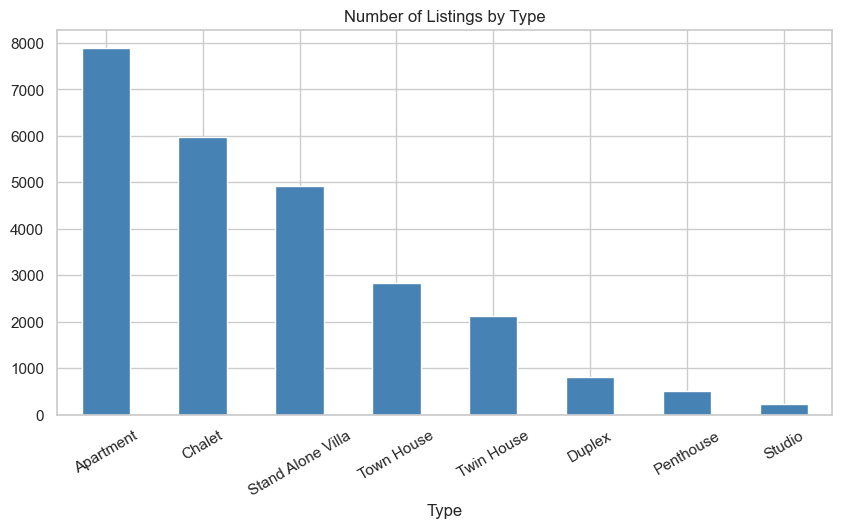

In [17]:
plt.figure(figsize=(10, 5))
df['Type'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Number of Listings by Type')
plt.xticks(rotation=30)
plt.show()

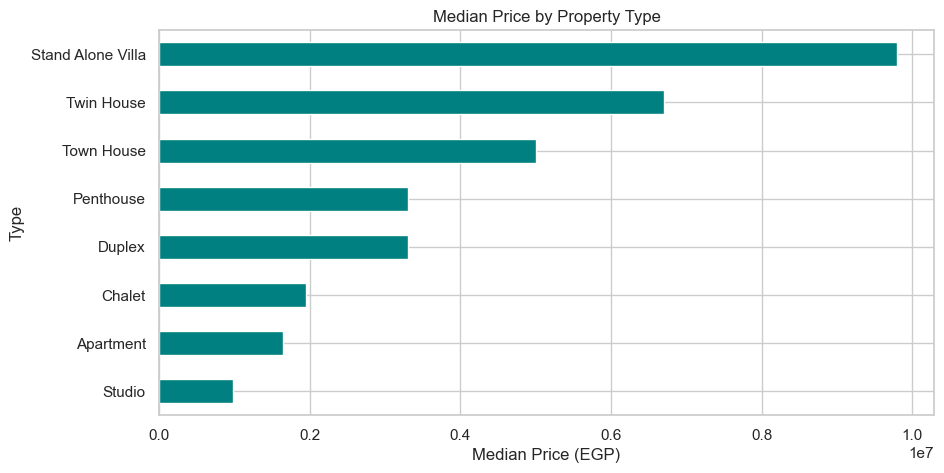

In [18]:
plt.figure(figsize=(10, 5))
df.groupby('Type')['Price'].median().sort_values().plot(kind='barh', color='teal')
plt.title('Median Price by Property Type')
plt.xlabel('Median Price (EGP)')
plt.show()

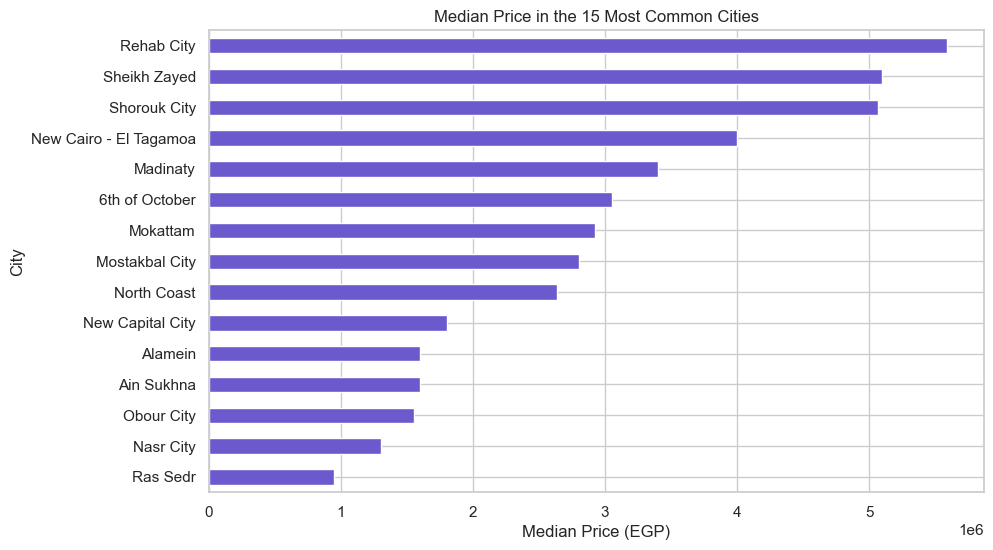

In [19]:
top_cities = df['City'].value_counts().head(15).index

plt.figure(figsize=(10, 6))
df[df['City'].isin(top_cities)].groupby('City')['Price'].median().sort_values().plot(kind='barh', color='slateblue')
plt.title('Median Price in the 15 Most Common Cities')
plt.xlabel('Median Price (EGP)')
plt.show()

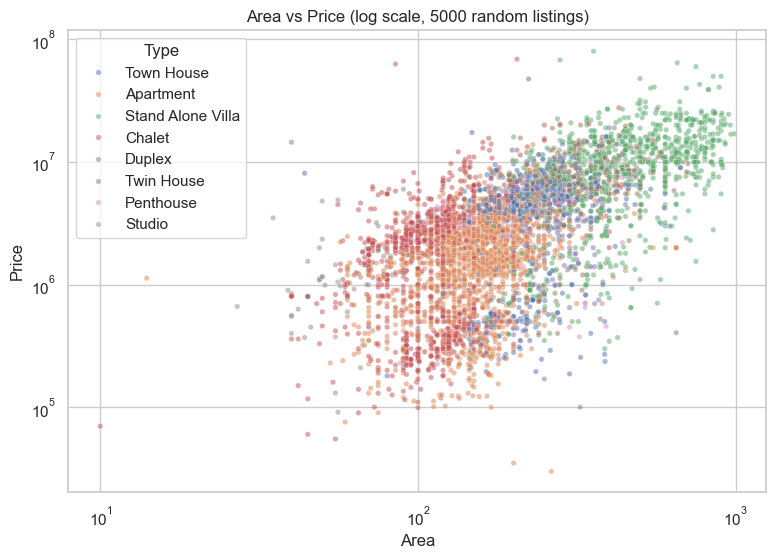

In [20]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x='Area', y='Price', hue='Type', data=df.sample(5000, random_state=42), alpha=0.5, s=15)
plt.xscale('log')
plt.yscale('log')
plt.title('Area vs Price (log scale, 5000 random listings)')
plt.show()

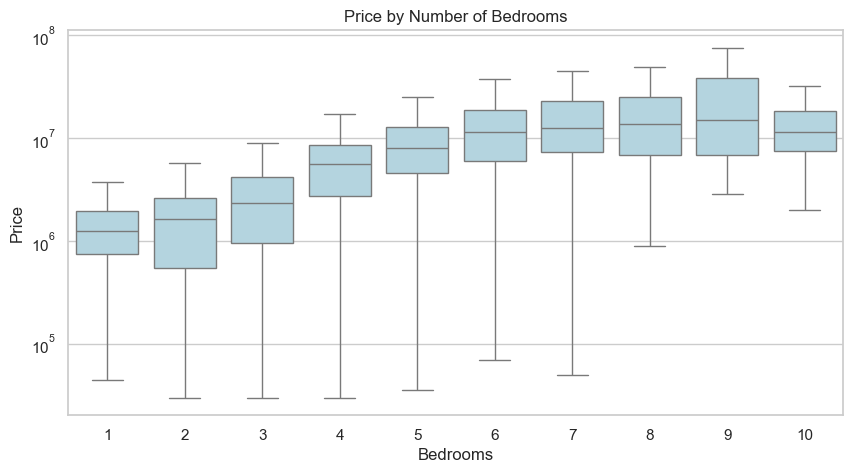

In [21]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['Bedrooms'].astype('Int64'), y=df['Price'], color='lightblue', showfliers=False)
plt.yscale('log')
plt.title('Price by Number of Bedrooms')
plt.show()

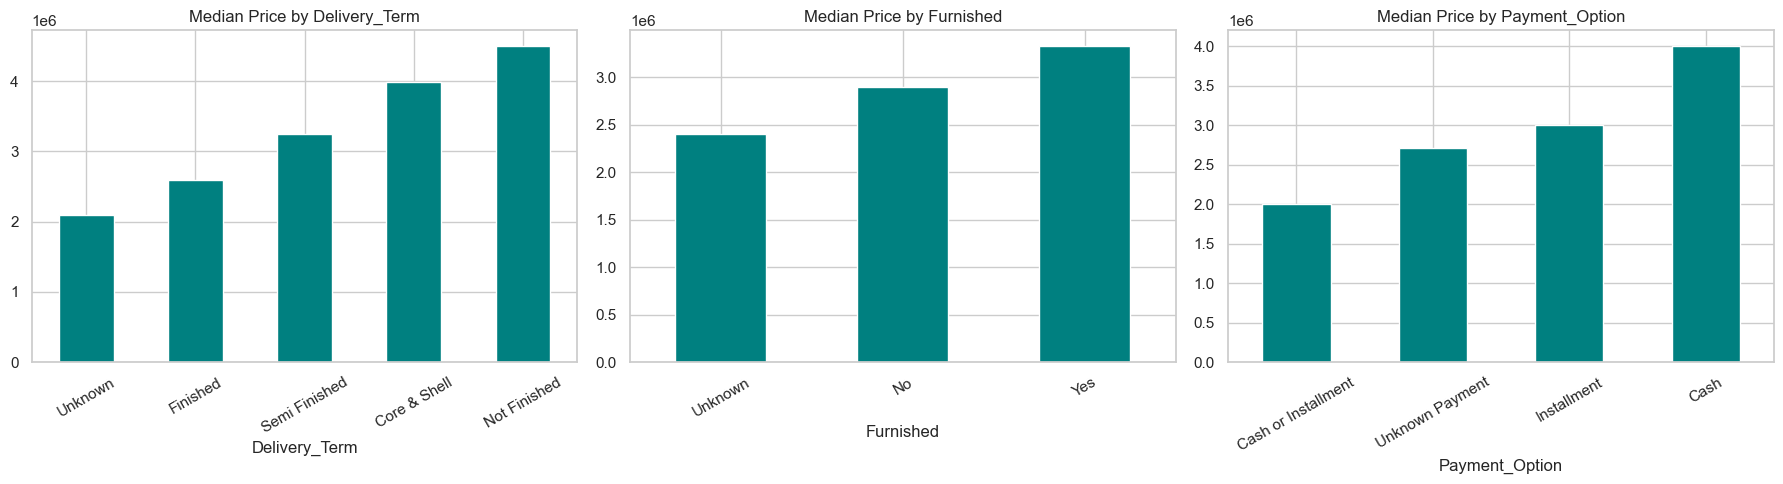

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['Delivery_Term', 'Furnished', 'Payment_Option']):
    df.groupby(col)['Price'].median().sort_values().plot(kind='bar', color='teal', ax=ax[i])
    ax[i].set_title('Median Price by ' + col)
    ax[i].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

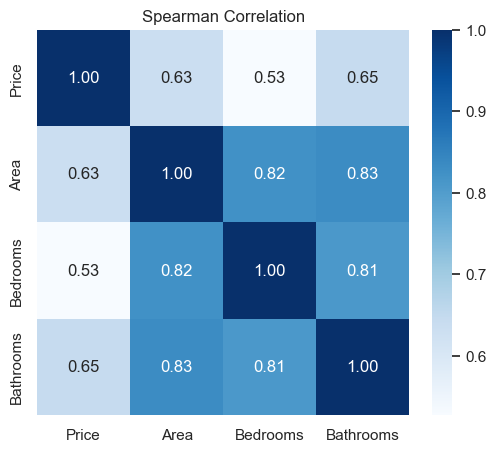

In [23]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Price', 'Area', 'Bedrooms', 'Bathrooms']].corr(method='spearman'), annot=True, cmap='Blues', fmt='.2f')
plt.title('Spearman Correlation')
plt.show()

**EDA findings**
- **Target:** the price is very right-skewed (skewness 6.8, kurtosis 116). log(Price) has skewness −0.26 → the models predict log(Price).
- **Type:** Stand Alone Villa is the most expensive (median 9.8M EGP), then Twin House (6.7M) and Town House (5.0M). Studio (0.99M) and Apartment (1.65M) are the cheapest.
- **Location matters a lot:** in the 15 most common cities the median price goes from 0.95M (Ras Sedr) to 5.6M (Rehab City). New Cairo (6,371 listings) and North Coast (5,771) dominate the data.
- **Area & rooms:** the price grows with the area almost in a straight line on the log-log plot. Spearman correlation with the price: Bathrooms 0.65, Area 0.63, Bedrooms 0.53.
- Area, Bedrooms and Bathrooms are strongly correlated with each other (≈ 0.82) – they all describe the size.
- **Surprise:** *Not Finished* / *Core & Shell* units have a **higher** median price than *Finished* ones. They are mostly villas and town houses in new compounds,
  so the effect comes from the property type, not from the finishing → the price depends on **combinations** of features, which non-linear models can learn.
- **Payment:** *Cash* listings have the highest median (4.0M) and *Cash or Installment* the lowest (2.0M) – some installment listings seem to show only the down-payment (see Outliers).

# Outliers

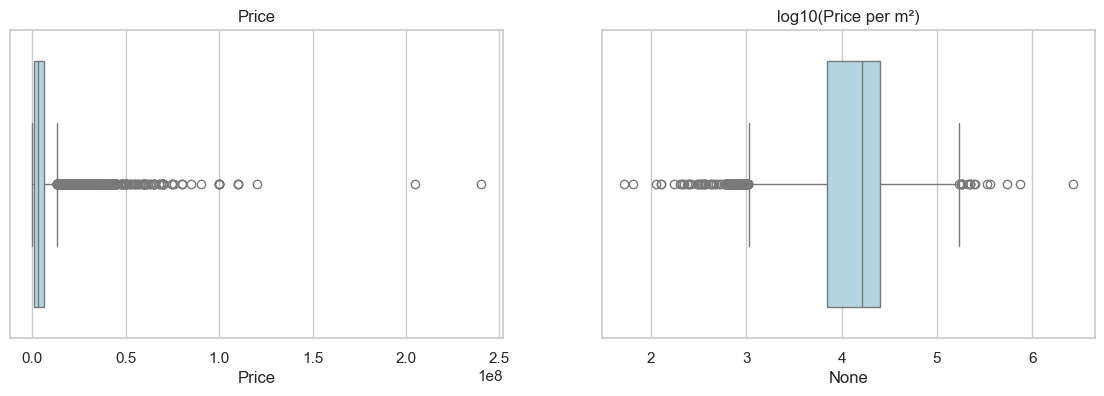

In [24]:
price_per_m2 = df['Price'] / df['Area']   # used for analysis only, never as a feature (it contains the target)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df['Price'], color='lightblue', ax=ax[0])
ax[0].set_title('Price')
sns.boxplot(x=np.log10(price_per_m2), color='lightblue', ax=ax[1])
ax[1].set_title('log10(Price per m²)')
plt.show()

In [25]:
q1 = df['Price'].quantile(0.25)
q3 = df['Price'].quantile(0.75)
print('Listings above the raw-price IQR limit :', (df['Price'] > q3 + 1.5 * (q3 - q1)).sum())
print(price_per_m2.describe().round(0))

Listings above the raw-price IQR limit : 1893
count      24908.0
mean       18323.0
std        23123.0
min           53.0
25%         7074.0
50%        16355.0
75%        25217.0
max      2636364.0
dtype: float64


In [26]:
df[price_per_m2 < 1000][['Type', 'Price', 'Area', 'Compound', 'City', 'Payment_Option']].head(10)

,Type,Price,Area,Compound,City,Payment_Option
157,Apartment,36000.0,161.0,Unknown,New Cairo - El Tagamoa,Cash or Installment
601,NaN,125800.0,180.0,Beit Al Watan,6th of October,Installment
765,Apartment,110000.0,121.0,Tag Sultan,New Cairo - El Tagamoa,Cash or Installment
950,Apartment,129000.0,130.0,Badya Palm Hills,6th of October,Unknown Payment
1058,Apartment,110000.0,120.0,Gardenia,Nasr City,Cash
1190,Apartment,123000.0,165.0,Sarai,Mostakbal City,Installment
1198,Apartment,122000.0,147.0,Sarai,Mostakbal City,Installment
1210,Apartment,124000.0,141.0,Taj City,Nasr City,Installment
1451,Duplex,324000.0,378.0,De Joya,New Capital City,Installment
1561,Apartment,90000.0,115.0,Unknown,Zahraa Al Maadi,Cash or Installment


- Very expensive villas are **real** listings, so IQR on the raw price would wrongly delete thousands of real villas.
- The real problem is listings like a **120 m² chalet for 100,000 EGP** (≈ 800 EGP/m²) – most likely the down-payment was typed as the price.
- So outliers are judged by **price per m²** (log scale), using the **IQR rule**.
- The IQR limits are learned **after the split from the training data only**, then the same rule is applied to the test set.

# Feature Engineering

In [27]:
df['Log_Area'] = np.log1p(df['Area'])                  # price grows with area in a log-log way (see scatter plot)
df['Area_per_Bedroom'] = df['Area'] / df['Bedrooms']   # bigger rooms -> more luxury property
df[['Area', 'Log_Area', 'Bedrooms', 'Area_per_Bedroom']].head()

,Area,Log_Area,Bedrooms,Area_per_Bedroom
0,400.0,5.993961,3.0,133.333333
1,160.0,5.081404,3.0,53.333333
2,165.0,5.111988,3.0,55.000000
3,230.0,5.442418,3.0,76.666667
4,160.0,5.081404,2.0,80.000000


- Both features are simple row-by-row formulas (they don't learn anything from other rows), so creating them before the split causes **no leakage**.
- `Price per m²` is **not** used as a feature because it is calculated from the target.

# Feature Selection

In [28]:
num_cols = ['Bedrooms', 'Bathrooms', 'Area', 'Log_Area', 'Area_per_Bedroom']
cat_cols = ['Type', 'Furnished', 'Level', 'Compound', 'Payment_Option', 'Delivery_Date', 'Delivery_Term', 'City']

df[cat_cols].nunique()

Type                8
Furnished           3
Level              14
Compound          559
Payment_Option      4
Delivery_Date      10
Delivery_Term       5
City              179
dtype: int64

In [29]:
df[num_cols].corrwith(np.log1p(df['Price']), method='spearman').sort_values(ascending=False)

Bathrooms           0.645893
Area                0.632881
Log_Area            0.632881
Area_per_Bedroom    0.527565
Bedrooms            0.527455
dtype: float64

**Feature selection decisions**
- All 5 numeric features have a clear positive correlation with log(Price) (0.53 – 0.65) → all kept.
- Every categorical column showed a clear price difference in the EDA → all kept.
- `Compound` (559 values) and `City` (179 values) have many rare values. Instead of 700+ one-hot columns, `OneHotEncoder(min_frequency=10)`
  keeps only categories with at least 10 listings and groups the rest into one *infrequent* column → fewer noisy columns and less overfitting.
- Area / Bedrooms / Bathrooms are correlated (≈ 0.82) but kept: each adds some information (e.g. more bathrooms → more luxury),
  and the models used (regularized linear, trees, SVR) handle correlated features. The permutation importance at the end confirms each of them is useful.

# Split data

In [30]:
from sklearn.model_selection import train_test_split

X = df[num_cols + cat_cols]
y = np.log1p(df['Price'])   # log target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (20322, 13)  y_train =  (20322,)
X_test  =  (5081, 13)  y_test  =  (5081,)


## Remove outliers (IQR limits from the training data only)

In [31]:
train_ppm = np.log(np.expm1(y_train) / X_train['Area'])   # log(price per m2)
q1 = train_ppm.quantile(0.25)
q3 = train_ppm.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print('Accepted price per m2 :', round(np.exp(lower)), 'to', round(np.exp(upper)), 'EGP')

def remove_outliers(X_part, y_part):
    ppm = np.log(np.expm1(y_part) / X_part['Area'])
    keep = ppm.isna() | ((ppm >= lower) & (ppm <= upper))   # rows without Area are kept
    print('removed rows :', (~keep).sum())
    return X_part[keep], y_part[keep]

X_train, y_train = remove_outliers(X_train, y_train)
X_test, y_test = remove_outliers(X_test, y_test)
print('X_train = ', X_train.shape, ' X_test = ', X_test.shape)

Accepted price per m2 : 1030 to 171739 EGP
removed rows : 200
removed rows : 38
X_train =  (20122, 13)  X_test =  (5043, 13)


# Preprocessing (Pipeline + ColumnTransformer)

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [33]:
print('Columns after preprocessing :', preprocessor.fit_transform(X_train).shape[1])

Columns after preprocessing : 322


- **Imputation:** median for numbers (robust to outliers), `Unknown` for categories.
- **Scaling:** `StandardScaler` – needed by KNN, SVR and the regularized linear models (trees don't need it, but it doesn't hurt them).
- **Encoding:** `OneHotEncoder` because the categories have no order. `Level` is kept as a category because it mixes numbers and words (`Ground`, `Highest`, `Unknown`).
  Categories that appear fewer than 10 times are grouped into one *infrequent* column, and new categories at prediction time don't break the model.
- Everything is inside a **Pipeline**, so `fit` happens on the training folds only → **no data leakage** in cross-validation, tuning or deployment.

# Models

| Model | Why it is tried |
|---|---|
| Linear Regression | simple baseline, easy to explain |
| Ridge / Lasso / ElasticNet | linear + regularization (L2 / L1 / both) to control overfitting with 300+ one-hot columns |
| KNN Regressor | the price of the most similar houses |
| Decision Tree | non-linear rules, easy to read, but overfits |
| Random Forest / Extra Trees | many trees averaged → less overfitting |
| SVR | non-linear (RBF kernel), works well on scaled data |
| Gradient Boosting / AdaBoost | boosting: each tree corrects the errors of the previous ones |
| XGBoost / LightGBM | fast, regularized gradient boosting – usually the best on tabular data |

**Excluded:** Logistic Regression, Naive Bayes and the other classifiers (this is regression, not classification).
Polynomial Regression is excluded because with 300+ one-hot columns the polynomial features explode, and the tree/boosting models already learn the interactions.

In [34]:
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [35]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.001),
    'ElasticNet': ElasticNet(alpha=0.001, l1_ratio=0.5),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'SVR': SVR(kernel='rbf'),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'LightGBM': LGBMRegressor(random_state=42, verbose=-1),
}

## Model comparison with 5-fold cross-validation
Each model is put in the same Pipeline with the preprocessor and evaluated on the **training data only**
(the scores are on the log-price scale).

In [36]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error', 'MSE': 'neg_mean_squared_error', 'RMSE': 'neg_root_mean_squared_error'}

results = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    cv = cross_validate(pipe, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    results[name] = {
        'Train R2': cv['train_R2'].mean(),
        'CV R2': cv['test_R2'].mean(),
        'CV MAE': -cv['test_MAE'].mean(),
        'CV MSE': -cv['test_MSE'].mean(),
        'CV RMSE': -cv['test_RMSE'].mean(),
        'Fit time (s)': cv['fit_time'].mean(),
    }
    print(f"{name:18s}  CV R2 = {results[name]['CV R2']:.4f}")

Linear Regression   CV R2 = 0.6118


Ridge               CV R2 = 0.6120


Lasso               CV R2 = 0.5904


ElasticNet          CV R2 = 0.5990


KNN                 CV R2 = 0.6279


Decision Tree       CV R2 = 0.3960


... (3 outputs left out)

AdaBoost            CV R2 = 0.4259


Extra Trees         CV R2 = 0.6493


XGBoost             CV R2 = 0.6680


LightGBM            CV R2 = 0.6629


In [37]:
comparison = pd.DataFrame(results).T.sort_values('CV R2', ascending=False)
comparison.to_csv('../results/model_comparison.csv')
comparison.round(4)

,Train R2,CV R2,CV MAE,CV MSE,CV RMSE,Fit time (s)
SVR,0.7299,0.6752,0.4548,0.4684,0.6842,18.2490
XGBoost,0.7444,0.6680,0.5016,0.4787,0.6917,0.4198
Random Forest,0.9422,0.6648,0.4755,0.4832,0.6950,46.6220
LightGBM,0.7049,0.6629,0.5091,0.4860,0.6970,1.7609
Extra Trees,0.9847,0.6493,0.4638,0.5055,0.7108,80.0839
KNN,0.7539,0.6279,0.5132,0.5365,0.7323,0.1136
Ridge,0.6226,0.6120,0.5676,0.5595,0.7478,0.1829
Linear Regression,0.6227,0.6118,0.5677,0.5598,0.7480,0.2218
Gradient Boosting,0.6205,0.6083,0.5773,0.5648,0.7514,2.1096
ElasticNet,0.6049,0.5990,0.5840,0.5782,0.7602,0.9110


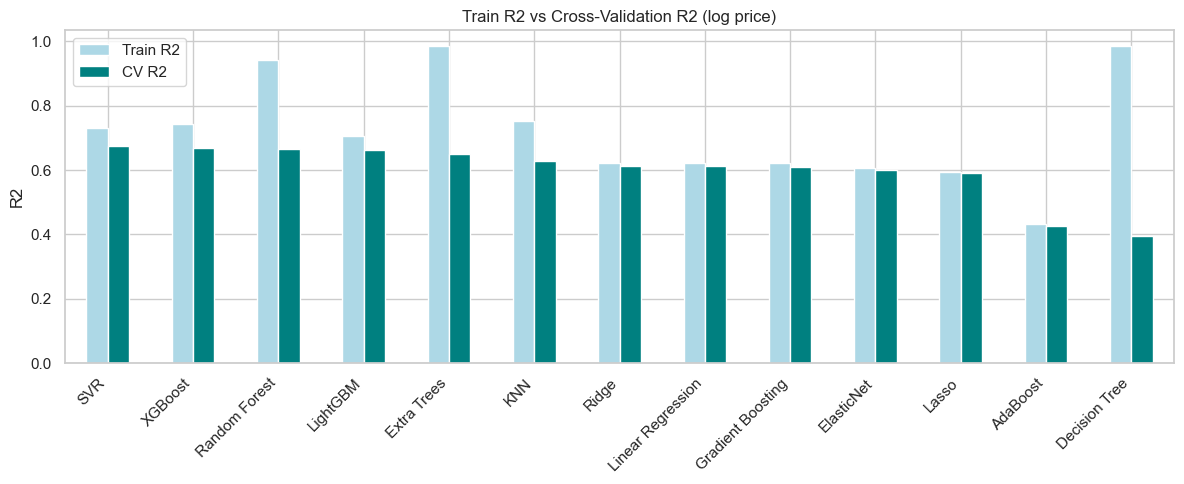

In [38]:
comparison[['Train R2', 'CV R2']].plot(kind='bar', figsize=(12, 5), color=['lightblue', 'teal'])
plt.title('Train R2 vs Cross-Validation R2 (log price)')
plt.ylabel('R2')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../results/model_comparison.png', dpi=100)
plt.show()

**Comparison results (5-fold CV on the training data, log price)**
- **Best models:** SVR (CV R² 0.675), XGBoost (0.668), Random Forest (0.665), LightGBM (0.663). Non-linear models win because the price depends on
  combinations of features (a villa in North Coast ≠ a villa in Nasr City).
- **Linear models** (Linear Regression, Ridge, Lasso, ElasticNet ≈ 0.59 – 0.61): train and CV scores are almost equal → they **underfit** (too simple).
  Ridge ≈ Linear Regression because there are enough rows; Lasso / ElasticNet drop some one-hot columns and lose a little accuracy.
- **Decision Tree:** train R² 0.98 but CV R² 0.40 → strong **overfitting** (it memorizes the training data). Random Forest and Extra Trees reduce it by
  averaging many trees, but still show a large train/CV gap (0.94 – 0.98 vs 0.65 – 0.66).
- **AdaBoost** (0.43) and sklearn **Gradient Boosting** (0.61) underfit with their default shallow trees (depth 3); XGBoost / LightGBM use deeper trees and do much better.
- **KNN** (0.63) is acceptable, but distances on 322 mostly one-hot columns are not very meaningful.
- **SVR** has the best CV score and a small train/CV gap (0.73 vs 0.68) → it generalizes well. It is slower to train (≈ 17 s per fit) but predicts fast.
- The **top 3 (SVR, XGBoost, Random Forest)** are tuned with GridSearchCV.

# GridSearchCV (top 3 models)

A parameter grid is prepared for every model; the **top 3 models** from the comparison table are tuned with 5-fold cross-validation on the training data.

In [39]:
param_grids = {
    'Linear Regression': {'model__fit_intercept': [True, False]},
    'Ridge': {'model__alpha': [0.1, 1, 10, 100]},
    'Lasso': {'model__alpha': [0.0001, 0.001, 0.01]},
    'ElasticNet': {'model__alpha': [0.0001, 0.001, 0.01], 'model__l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'model__n_neighbors': [5, 10, 20], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [10, 20, None], 'model__min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'model__n_estimators': [200], 'model__max_features': [0.3, 0.5], 'model__min_samples_leaf': [1, 2]},
    'SVR': {'model__C': [1, 3, 10], 'model__gamma': ['scale', 0.05]},
    'Gradient Boosting': {'model__n_estimators': [300, 600], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 5]},
    'AdaBoost': {'model__n_estimators': [50, 100], 'model__learning_rate': [0.1, 1.0]},
    'Extra Trees': {'model__n_estimators': [200], 'model__max_features': [0.3, 0.5], 'model__min_samples_leaf': [1, 2]},
    'XGBoost': {'model__n_estimators': [300, 600], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [6, 8]},
    'LightGBM': {'model__n_estimators': [300, 600], 'model__learning_rate': [0.05, 0.1], 'model__num_leaves': [31, 63]},
}

In [40]:
top_models = comparison.index[:3]
grids = {}

for name in top_models:
    pipe = Pipeline([('preprocessor', preprocessor), ('model', models[name])])
    grid = GridSearchCV(pipe, param_grids[name], cv=kfold, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    grids[name] = grid

    print('=' * 60)
    print(name)
    print('Parameter grid :', param_grids[name])
    print('best_params_   :', grid.best_params_)
    print('best_score_    :', round(grid.best_score_, 4), '(CV R2)')

SVR
Parameter grid : {'model__C': [1, 3, 10], 'model__gamma': ['scale', 0.05]}
best_params_   : {'model__C': 3, 'model__gamma': 'scale'}
best_score_    : 0.6841 (CV R2)


XGBoost
Parameter grid : {'model__n_estimators': [300, 600], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [6, 8]}
best_params_   : {'model__learning_rate': 0.1, 'model__max_depth': 8, 'model__n_estimators': 600}
best_score_    : 0.6811 (CV R2)


Random Forest
Parameter grid : {'model__n_estimators': [200], 'model__max_features': [0.3, 0.5], 'model__min_samples_leaf': [1, 2]}
best_params_   : {'model__max_features': 0.3, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
best_score_    : 0.6725 (CV R2)


## Before vs after tuning (cross-validation R2)

In [41]:
tuning = pd.DataFrame({
    'CV R2 before tuning': comparison.loc[top_models, 'CV R2'],
    'CV R2 after tuning': [grids[name].best_score_ for name in top_models],
})
tuning['Improvement'] = tuning['CV R2 after tuning'] - tuning['CV R2 before tuning']
tuning['Best params'] = [grids[name].best_params_ for name in top_models]
tuning = tuning.sort_values('CV R2 after tuning', ascending=False)
tuning.to_csv('../results/tuning_results.csv')
tuning

,CV R2 before tuning,CV R2 after tuning,Improvement,Best params
SVR,0.675165,0.684147,0.008981,"{'model__C': 3, 'model__gamma': 'scale'}"
XGBoost,0.667975,0.681052,0.013077,"{'model__learning_rate': 0.1, 'model__max_dept..."
Random Forest,0.664794,0.672533,0.007739,"{'model__max_features': 0.3, 'model__min_sampl..."


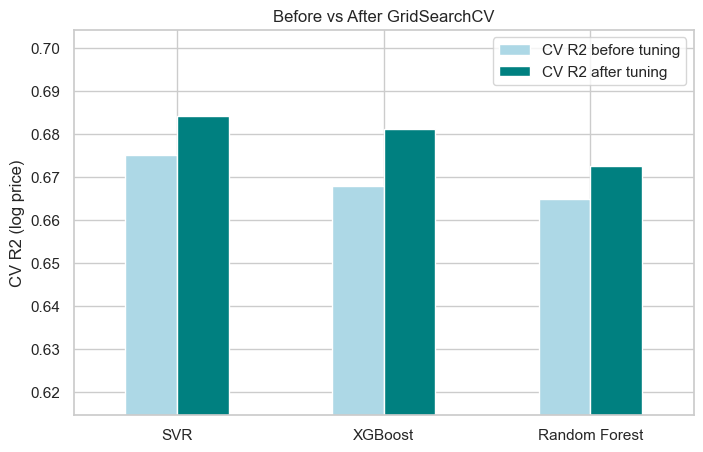

In [42]:
tuning[['CV R2 before tuning', 'CV R2 after tuning']].plot(kind='bar', figsize=(8, 5), color=['lightblue', 'teal'])
plt.ylim(tuning['CV R2 before tuning'].min() - 0.05, tuning['CV R2 after tuning'].max() + 0.02)
plt.title('Before vs After GridSearchCV')
plt.ylabel('CV R2 (log price)')
plt.xticks(rotation=0)
plt.show()

In [43]:
best_name = tuning.index[0]   # chosen by cross-validation score, not by the test set
best_model = grids[best_name].best_estimator_
print('Best model :', best_name)
print('Best params:', grids[best_name].best_params_)

Best model : SVR
Best params: {'model__C': 3, 'model__gamma': 'scale'}


# Final Evaluation on the Test Set

The test set is used **only now**, once, for the chosen model. The metrics are shown on the log scale and in EGP.

In [44]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

# the same model before tuning, to compare on the test set
base_model = Pipeline([('preprocessor', preprocessor), ('model', models[best_name])]).fit(X_train, y_train)

y_pred_base = base_model.predict(X_test)
y_pred = best_model.predict(X_test)

y_test_egp = np.expm1(y_test)
y_pred_egp = np.expm1(y_pred)

final = pd.DataFrame({
    'Before tuning (log)': regression_metrics(y_test, y_pred_base),
    'After tuning (log)': regression_metrics(y_test, y_pred),
    'Before tuning (EGP)': regression_metrics(y_test_egp, np.expm1(y_pred_base)),
    'After tuning (EGP)': regression_metrics(y_test_egp, y_pred_egp),
}).T
final.to_csv('../results/final_test_metrics.csv')
final.style.format('{:,.4f}')

,MAE,MSE,RMSE,R2
Before tuning (log),0.4536,0.4754,0.6895,0.6668
After tuning (log),0.4458,0.4670,0.6834,0.6727
Before tuning (EGP),"1,691,479.2114","25,019,714,353,357.0469","5,001,971.0468",0.5362
After tuning (EGP),"1,689,379.1405","24,601,315,906,117.0508","4,959,971.3614",0.5439


In [45]:
ape = np.abs(y_pred_egp - y_test_egp) / y_test_egp * 100   # absolute percentage error
print('Median error             :', round(np.median(ape), 1), '%')
print('Predictions within 20%   :', round((ape <= 20).mean() * 100, 1), '%')
print('Predictions within 50%   :', round((ape <= 50).mean() * 100, 1), '%')
print('Median absolute error    :', f'{np.median(np.abs(y_pred_egp - y_test_egp)):,.0f}', 'EGP')

Median error             : 25.1 %
Predictions within 20%   : 43.2 %
Predictions within 50%   : 73.6 %
Median absolute error    : 670,000 EGP


## Actual vs Predicted

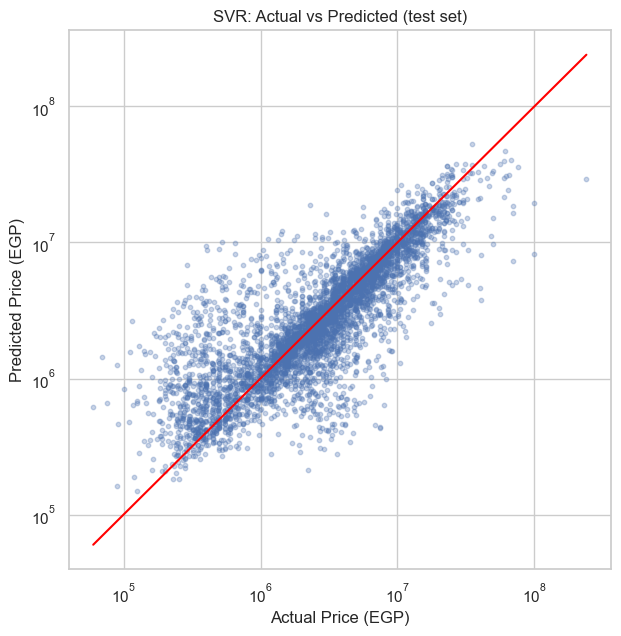

In [46]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_egp, y_pred_egp, alpha=0.3, s=10)
lim = [y_test_egp.min(), y_test_egp.max()]
plt.plot(lim, lim, color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Actual Price (EGP)')
plt.ylabel('Predicted Price (EGP)')
plt.title(best_name + ': Actual vs Predicted (test set)')
plt.savefig('../results/actual_vs_predicted.png', dpi=100)
plt.show()

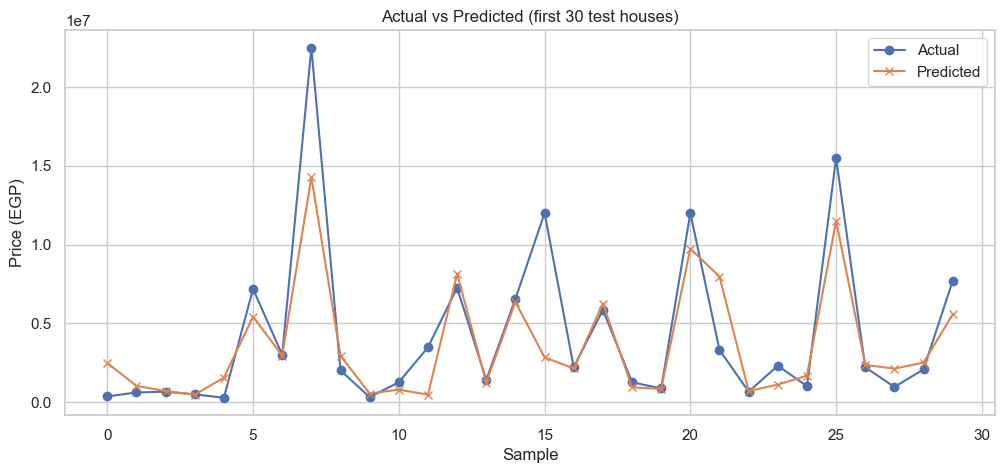

In [47]:
plt.figure(figsize=(12, 5))
plt.plot(range(30), y_test_egp.values[:30], marker='o', label='Actual')
plt.plot(range(30), y_pred_egp[:30], marker='x', label='Predicted')
plt.xlabel('Sample')
plt.ylabel('Price (EGP)')
plt.title('Actual vs Predicted (first 30 test houses)')
plt.legend()
plt.show()

## Residuals

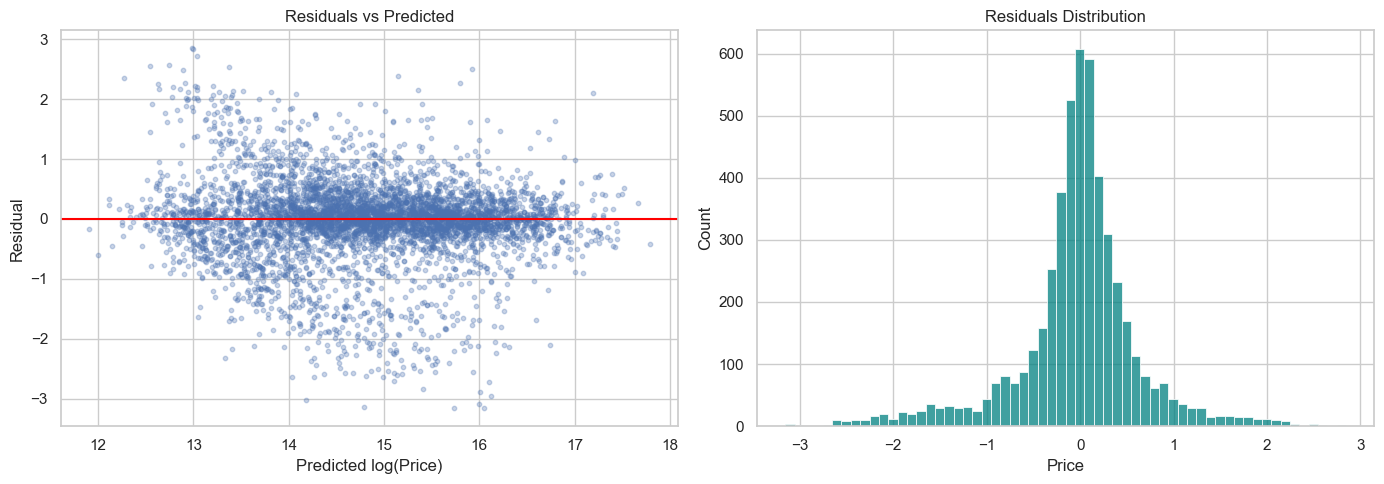

In [48]:
residuals = y_test - y_pred   # log scale: residual of 0.2 ~ the price is 22% higher than predicted

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_pred, residuals, alpha=0.3, s=10)
ax[0].axhline(0, color='red')
ax[0].set_xlabel('Predicted log(Price)')
ax[0].set_ylabel('Residual')
ax[0].set_title('Residuals vs Predicted')
sns.histplot(residuals, bins=60, color='teal', ax=ax[1])
ax[1].set_title('Residuals Distribution')
plt.tight_layout()
plt.savefig('../results/residuals.png', dpi=100)
plt.show()

## Error by property type

In [49]:
errors = pd.DataFrame({'Type': X_test['Type'], 'APE %': ape})
errors.groupby('Type')['APE %'].agg(['count', 'median']).sort_values('median').round(1)

,count,median
Type,,
Twin House,427,17.8
Apartment,1583,20.2
Town House,549,23.0
Penthouse,99,23.4
Duplex,163,25.5
Studio,50,27.7
Stand Alone Villa,983,28.0
Chalet,1164,34.7


## Which features matter? (permutation importance on the test set)

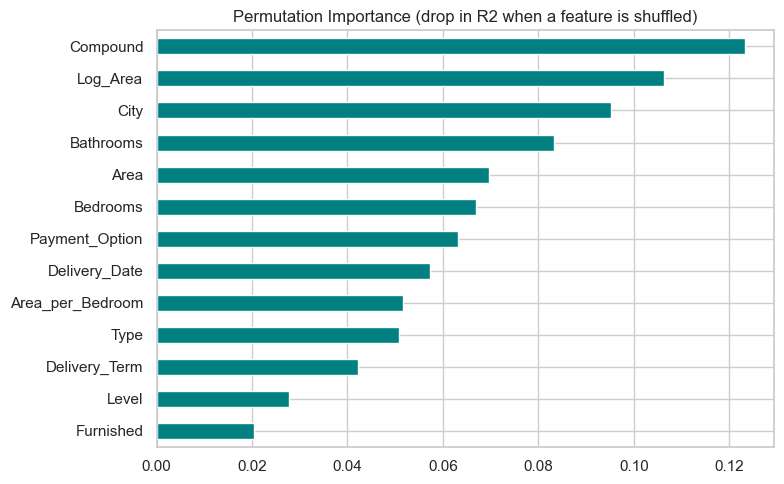

In [50]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=42, scoring='r2', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='teal')
plt.title('Permutation Importance (drop in R2 when a feature is shuffled)')
plt.tight_layout()
plt.savefig('../results/feature_importance.png', dpi=100)
plt.show()

**Interpretation of errors & discussion of model performance**
- **Before vs after tuning (test set):** R² (log) 0.667 → **0.673**, RMSE (log) 0.690 → 0.683. Tuning gave a small but consistent improvement,
  and the test R² (0.673) is close to the CV score (0.684) → the model was not over-tuned and cross-validation was a reliable estimate.
- **Log scale vs EGP:** R² is 0.67 on log price but 0.54 in EGP. In EGP the errors of the few very expensive villas (tens of millions) dominate
  MSE / RMSE (RMSE ≈ 5.0M EGP, MAE ≈ 1.7M EGP). A **percentage** view is fairer: the median error is **25 %**, 43 % of the predictions are within ±20 %
  and 74 % within ±50 %.
- **Actual vs Predicted:** the points follow the red line well between 1M and 20M EGP. Very cheap listings (< 1M) are usually **over-predicted** –
  many of them are probably down-payments or wrong prices that passed the outlier filter. The most expensive villas (> 50M) are **under-predicted**
  because there are very few of them to learn from.
- **Residuals:** centered at 0, roughly bell-shaped, with no clear pattern against the predicted value → no systematic bias.
  The left tail (actual much lower than predicted) is longer, which matches the suspicious cheap listings above.
- **By property type:** Twin House (18 %) and Apartment (20 %) are predicted best (many similar listings). Chalets are the hardest (35 %):
  coastal prices depend on details that are not in the data (sea view, distance to the beach, season). Villas (28 %) vary a lot in land size and finishing.
- **Most important features:** Compound, Log_Area and City → **location and size** drive the price. Furnished and Level matter least.
- **Limits:** the data has no land area, view, building age, exact location or listing date, and part of the prices look wrong. This caps the accuracy
  at around R² ≈ 0.68 for all strong models (SVR, XGBoost, Random Forest and LightGBM all ended very close to each other).

# Save the model

In [51]:
import joblib
import json

# the whole pipeline (preprocessing + model) is saved, so the app needs no extra preprocessing code
joblib.dump(best_model, '../models/house_price_model.pkl', compress=3)

# dropdown values for the app
choices = {col: sorted(X_train[col].dropna().unique().tolist()) for col in cat_cols}
with open('../models/choices.json', 'w') as f:
    json.dump(choices, f, indent=2)

## Test the saved model on a new house

In [52]:
loaded_model = joblib.load('../models/house_price_model.pkl')

new_house = pd.DataFrame([{
    'Type': 'Apartment', 'Bedrooms': 3, 'Bathrooms': 2, 'Area': 150, 'Furnished': 'No', 'Level': '3',
    'Compound': 'Unknown', 'Payment_Option': 'Cash', 'Delivery_Date': 'Ready to move',
    'Delivery_Term': 'Finished', 'City': 'New Cairo - El Tagamoa',
}])
new_house['Log_Area'] = np.log1p(new_house['Area'])               # same feature engineering as above
new_house['Area_per_Bedroom'] = new_house['Area'] / new_house['Bedrooms']

price = np.expm1(loaded_model.predict(new_house)[0])
print(f'Predicted price: {price:,.0f} EGP')

Predicted price: 1,604,883 EGP


# Gradio App (deployment)
The saved pipeline (`loaded_model`) and the dropdown values (`choices`) are put into a small web app. The user describes the property,
the app builds the same engineered features (`Log_Area`, `Area_per_Bedroom`), the model predicts **log(price)** and `np.expm1` turns it back into EGP.

- Run the cell below to open the app **inside the notebook** (or at the local link it prints).
- The same code is in [`app.py`](../app.py), which is the file used for the live deployment on Hugging Face Spaces.

In [53]:
import gradio as gr

def predict_price(Type, Bedrooms, Bathrooms, Area, Furnished, Level, Compound,
                  Payment_Option, Delivery_Date, Delivery_Term, City):
    house = pd.DataFrame([{
        'Type': Type, 'Bedrooms': Bedrooms, 'Bathrooms': Bathrooms, 'Area': Area,
        'Furnished': Furnished, 'Level': Level, 'Compound': Compound,
        'Payment_Option': Payment_Option, 'Delivery_Date': Delivery_Date,
        'Delivery_Term': Delivery_Term, 'City': City,
    }])
    house['Log_Area'] = np.log1p(house['Area'])                 # same feature engineering as above
    house['Area_per_Bedroom'] = house['Area'] / house['Bedrooms']

    price = float(np.expm1(loaded_model.predict(house)[0]))      # the model predicts log(price)
    return f'{price:,.0f} EGP', f'{price / Area:,.0f} EGP per m²'

demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Dropdown(choices['Type'], value='Apartment', label='Type'),
        gr.Number(value=3, label='Bedrooms', precision=0),
        gr.Number(value=2, label='Bathrooms', precision=0),
        gr.Number(value=150, label='Area (m²)'),
        gr.Dropdown(choices['Furnished'], value='No', label='Furnished'),
        gr.Dropdown(choices['Level'], value='3', label='Level (floor)'),
        gr.Dropdown(choices['Compound'], value='Unknown', label='Compound'),
        gr.Dropdown(choices['Payment_Option'], value='Cash', label='Payment Option'),
        gr.Dropdown(choices['Delivery_Date'], value='Ready to move', label='Delivery Date'),
        gr.Dropdown(choices['Delivery_Term'], value='Finished', label='Delivery Term (finishing)'),
        gr.Dropdown(choices['City'], value='New Cairo - El Tagamoa', label='City'),
    ],
    outputs=[
        gr.Textbox(label='Predicted price'),
        gr.Textbox(label='Price per m²'),
    ],
    examples=[
        ['Apartment', 3, 2, 150, 'No', '3', 'Unknown', 'Cash', 'Ready to move', 'Finished', 'New Cairo - El Tagamoa'],
        ['Chalet', 2, 2, 110, 'No', 'Ground', 'Marassi', 'Cash or Installment', '2024', 'Finished', 'North Coast'],
        ['Stand Alone Villa', 5, 5, 450, 'No', 'Unknown', 'Unknown', 'Cash', 'Ready to move', 'Semi Finished', 'Sheikh Zayed'],
    ],
    title='Egypt House Price Prediction',
    description='Describe the property to get an estimated price (typical error ≈ 25 %).',
)

demo.launch()

Running on local URL:  http://127.0.0.1:7860

To create a public link, set `share=True` in `launch()`.


In [54]:
# quick check: the app function gives the same answer as the saved-model test above
for h in [['Apartment', 3, 2, 150, 'No', '3', 'Unknown', 'Cash', 'Ready to move', 'Finished', 'New Cairo - El Tagamoa'],
          ['Chalet', 2, 2, 110, 'No', 'Ground', 'Marassi', 'Cash or Installment', '2024', 'Finished', 'North Coast'],
          ['Stand Alone Villa', 5, 5, 450, 'No', 'Unknown', 'Unknown', 'Cash', 'Ready to move', 'Semi Finished', 'Sheikh Zayed']]:
    print(f'{h[0]:18s} {h[3]} m²  {h[10]:24s} ->', predict_price(*h)[0])

Apartment          150 m²  New Cairo - El Tagamoa   -> 1,604,883 EGP
Chalet             110 m²  North Coast              -> 5,971,395 EGP
Stand Alone Villa  450 m²  Sheikh Zayed             -> 7,048,006 EGP


# Conclusions & Recommendations

**Conclusions**
1. After cleaning (text → numbers, fixed labels, 96 rows without price, 1,862 duplicates, 238 price-per-m² outliers) **25,165 listings** were used.
2. The price is driven mainly by **location (Compound, City)** and **size (Area, Bathrooms, Bedrooms)**, then by property type, payment and delivery.
3. 13 regression models were compared with 5-fold cross-validation. Non-linear models (SVR, XGBoost, Random Forest, LightGBM) clearly beat the linear ones,
   and a single Decision Tree overfits badly.
4. After GridSearchCV the best model is **SVR (C = 3, gamma = 'scale')** with CV R² 0.684 and **test R² 0.673** (log price); the median error is **25 %**.
5. The whole Pipeline (imputation + scaling + one-hot encoding + SVR) is saved in `models/house_price_model.pkl` and deployed with Gradio (`app.py`).

**Recommendations**
- Use the app as a **first estimate** (typical error ± 25 %), not as an exact valuation – especially for chalets and luxury villas.
- **Better data gives the biggest gain:** add land area, view, finishing quality, building age, exact location and listing date,
  and separate the *total price* from the *down-payment* for installment listings.
- Train separate models (or add a region feature) for **coastal** (North Coast, Ain Sukhna) and **city** properties, because they behave differently.
- Try target encoding for Compound / City and CatBoost, and **retrain regularly** because prices in Egypt change fast with inflation.